# Занятие 11. GAN для обработки и генерации изображений (PyTorch)
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Реализуем облегчённую DCGAN (генератор + дискриминатор) на подвыборке MNIST.
2. Обучим сеть и подробно визуализируем процесс обучения (несколько графиков,
   учитывая сложность темы).
3. Продемонстрируем и обсудим схлопывание мод (mode collapse) на конкретном примере.
4. Сгенерируем и оценим итоговые изображения.
5. Реализуем простую реставрацию (устранение шума) повреждённого изображения
   при помощи автокодировщика, обученного в состязательном режиме -- иллюстрация
   связи GAN с суперразрешением/реставрацией снимков (раздел 5 теории).

**Набор данных:** MNIST (рукописные цифры), доступен напрямую через
`torchvision.datasets.MNIST`, скачивается автоматически без регистрации.

**Важно:** используется подвыборка из 2000 изображений одного класса цифры
(для ускорения и большей предсказуемости обучения на центральном процессоре).

---
## Шаг 1. Импорт библиотек и настройка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cpu')
print(f'Устройство вычислений: {device}')

Устройство вычислений: cpu


---
## Шаг 2. Загрузка подвыборки MNIST (цифра «7»)

Набор данных MNIST скачивается автоматически при первом запуске ячейки.
Для учебных целей и ускорения обучения на центральном процессоре ограничимся
одной цифрой (7) и подвыборкой из 2000 изображений.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),  # приводим значения пикселей к диапазону [-1, 1], согласуется с tanh на выходе генератора
])

full_mnist = datasets.MNIST(root='./mnist', train=True, download=True, transform=transform)

DIGIT_CLASS = 7
N_SUBSET = 2000
digit_indices = [i for i, label in enumerate(full_mnist.targets) if label == DIGIT_CLASS][:N_SUBSET]
mnist_subset = Subset(full_mnist, digit_indices)
dataloader = DataLoader(mnist_subset, batch_size=64, shuffle=True)

print(f'Отобрано изображений цифры "{DIGIT_CLASS}": {len(mnist_subset)}')

Отобрано изображений цифры "7": 2000


---
## Шаг 3. Визуализация обучающих изображений

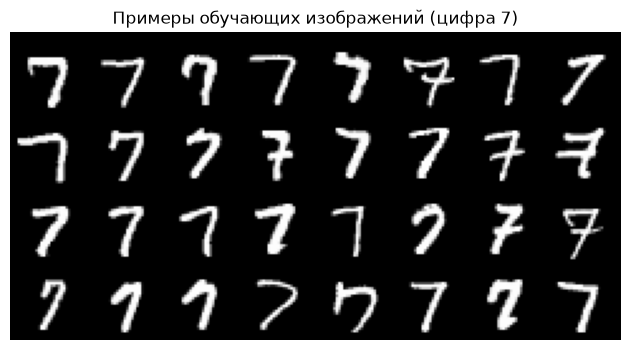

In [3]:
sample_batch, _ = next(iter(dataloader))
grid = make_grid(sample_batch[:32], nrow=8, normalize=True)
plt.figure(figsize=(9, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.title(f'Примеры обучающих изображений (цифра {DIGIT_CLASS})')
plt.axis('off')
plt.show()

---
## Шаг 4. Архитектура DCGAN: генератор и дискриминатор

Архитектура соответствует рекомендациям DCGAN, изложенным в теоретическом
материале, раздел 2: транспонированные свёртки в генераторе, свёртки с шагом
в дискриминаторе, пакетная нормализация, ReLU/Tanh в генераторе, LeakyReLU в
дискриминаторе.

In [4]:
LATENT_DIM = 64

class Generator(nn.Module):
    """Генератор: преобразует вектор шума в изображение 28x28."""

    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 128, 7, 1, 0, bias=False),  # 1x1 -> 7x7
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),           # 7x7 -> 14x14
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False),             # 14x14 -> 28x28
            nn.Tanh(),  # выход в диапазоне [-1, 1], согласуется с нормализацией данных
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), LATENT_DIM, 1, 1))


class Discriminator(nn.Module):
    """Дискриминатор: бинарный классификатор реальное/синтетическое изображение."""

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False),   # 28x28 -> 14x14
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),  # 14x14 -> 7x7
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 7, 1, 0, bias=False),   # 7x7 -> 1x1
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)


generator = Generator().to(device)
discriminator = Discriminator().to(device)
print(f'Число параметров генератора: {sum(p.numel() for p in generator.parameters()):,}')
print(f'Число параметров дискриминатора: {sum(p.numel() for p in discriminator.parameters()):,}')

Число параметров генератора: 533,888
Число параметров дискриминатора: 138,624


---
## Шаг 5. Функция потерь и оптимизаторы

In [5]:
criterion = nn.BCELoss()
optimizer_G = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

REAL_LABEL, FAKE_LABEL = 1.0, 0.0
fixed_noise = torch.randn(32, LATENT_DIM, device=device)  # фиксированный шум для отслеживания прогресса генератора
print('Функция потерь (бинарная кросс-энтропия) и оптимизаторы Adam определены.')

Функция потерь (бинарная кросс-энтропия) и оптимизаторы Adam определены.


---
## Шаг 6. Цикл состязательного обучения (формула 1 теоретического материала)

In [6]:
import time

NUM_EPOCHS = 40
history = {'loss_D': [], 'loss_G': [], 'D_accuracy_real': [], 'D_accuracy_fake': []}
snapshots = []  # сохраняем сгенерированные изображения через несколько эпох для визуализации прогресса

t_start = time.time()
for epoch in range(NUM_EPOCHS):
    loss_D_epoch, loss_G_epoch, acc_real_epoch, acc_fake_epoch, n_batches = 0.0, 0.0, 0.0, 0.0, 0

    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # --- Шаг обучения дискриминатора ---
        discriminator.zero_grad()
        real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)
        output_real = discriminator(real_images)
        loss_D_real = criterion(output_real, real_labels)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = generator(noise)
        fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)
        output_fake = discriminator(fake_images.detach())
        loss_D_fake = criterion(output_fake, fake_labels)

        loss_D = loss_D_real + loss_D_fake
        loss_D.backward()
        optimizer_D.step()

        # --- Шаг обучения генератора ---
        generator.zero_grad()
        output_fake_for_G = discriminator(fake_images)
        loss_G = criterion(output_fake_for_G, real_labels)  # генератор 'хочет' обмануть дискриминатор (метка 'реальное')
        loss_G.backward()
        optimizer_G.step()

        loss_D_epoch += loss_D.item()
        loss_G_epoch += loss_G.item()
        acc_real_epoch += (output_real > 0.5).float().mean().item()
        acc_fake_epoch += (output_fake < 0.5).float().mean().item()
        n_batches += 1

    history['loss_D'].append(loss_D_epoch / n_batches)
    history['loss_G'].append(loss_G_epoch / n_batches)
    history['D_accuracy_real'].append(acc_real_epoch / n_batches)
    history['D_accuracy_fake'].append(acc_fake_epoch / n_batches)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        with torch.no_grad():
            snapshot = generator(fixed_noise).detach().cpu()
        snapshots.append((epoch + 1, snapshot))
        print(f'Эпоха {epoch+1:3d}/{NUM_EPOCHS} | потери(D)={history["loss_D"][-1]:.3f} | '
              f'потери(G)={history["loss_G"][-1]:.3f} | точность(D,реальные)={history["D_accuracy_real"][-1]:.3f} | '
              f'точность(D,синтетич.)={history["D_accuracy_fake"][-1]:.3f}')

print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')

Эпоха   1/40 | потери(D)=0.258 | потери(G)=2.833 | точность(D,реальные)=0.969 | точность(D,синтетич.)=0.972
Эпоха   5/40 | потери(D)=0.004 | потери(G)=6.287 | точность(D,реальные)=1.000 | точность(D,синтетич.)=1.000
Эпоха  10/40 | потери(D)=0.001 | потери(G)=7.739 | точность(D,реальные)=1.000 | точность(D,синтетич.)=1.000
Эпоха  15/40 | потери(D)=1.061 | потери(G)=1.372 | точность(D,реальные)=0.754 | точность(D,синтетич.)=0.744
Эпоха  20/40 | потери(D)=1.036 | потери(G)=1.099 | точность(D,реальные)=0.782 | точность(D,синтетич.)=0.793
Эпоха  25/40 | потери(D)=1.013 | потери(G)=1.148 | точность(D,реальные)=0.767 | точность(D,синтетич.)=0.760
Эпоха  30/40 | потери(D)=0.973 | потери(G)=1.193 | точность(D,реальные)=0.796 | точность(D,синтетич.)=0.809
Эпоха  35/40 | потери(D)=0.911 | потери(G)=1.276 | точность(D,реальные)=0.837 | точность(D,синтетич.)=0.833
Эпоха  40/40 | потери(D)=0.934 | потери(G)=1.260 | точность(D,реальные)=0.764 | точность(D,синтетич.)=0.816

Время обучения: 98.9 секунд

---
## Шаг 7. Визуализация кривых обучения (потери и точность дискриминатора)

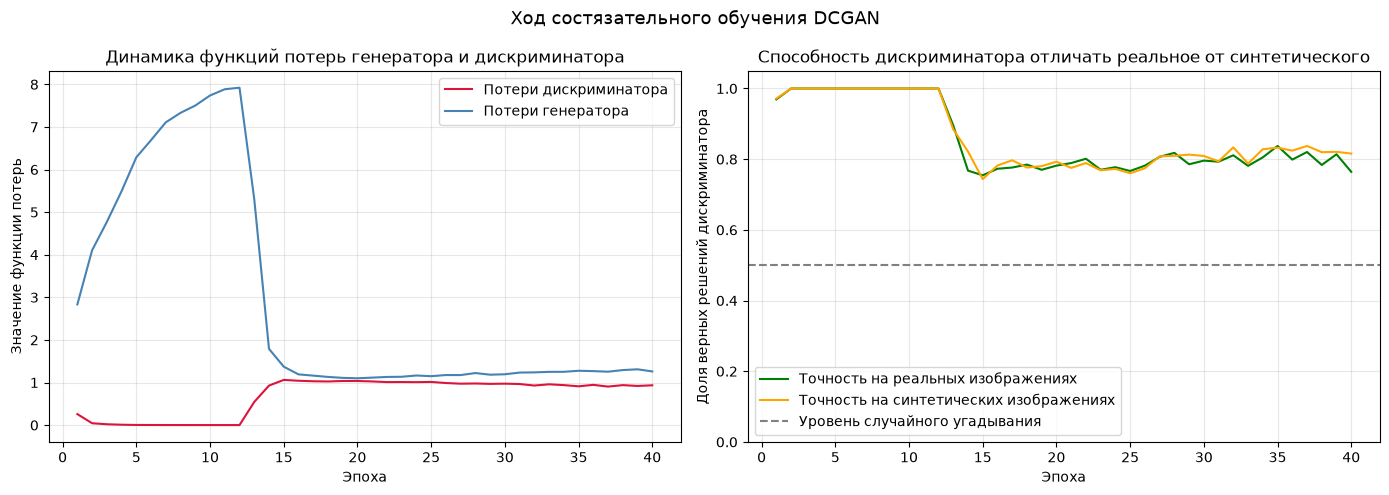

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, NUM_EPOCHS + 1)

axes[0].plot(epochs_range, history['loss_D'], label='Потери дискриминатора', color='crimson')
axes[0].plot(epochs_range, history['loss_G'], label='Потери генератора', color='steelblue')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
axes[0].set_title('Динамика функций потерь генератора и дискриминатора'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history['D_accuracy_real'], label='Точность на реальных изображениях', color='green')
axes[1].plot(epochs_range, history['D_accuracy_fake'], label='Точность на синтетических изображениях', color='orange')
axes[1].axhline(0.5, color='gray', linestyle='--', label='Уровень случайного угадывания')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Доля верных решений дискриминатора')
axes[1].set_title('Способность дискриминатора отличать реальное от синтетического'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_ylim(0, 1.05)

plt.suptitle('Ход состязательного обучения DCGAN', fontsize=13)
plt.tight_layout()
plt.show()

---
## Шаг 8. Визуализация прогресса генерации по эпохам

Одна из наиболее наглядных визуализаций для понимания GAN: как меняется
качество сгенерированных изображений в процессе обучения при фиксированном
входном шуме.

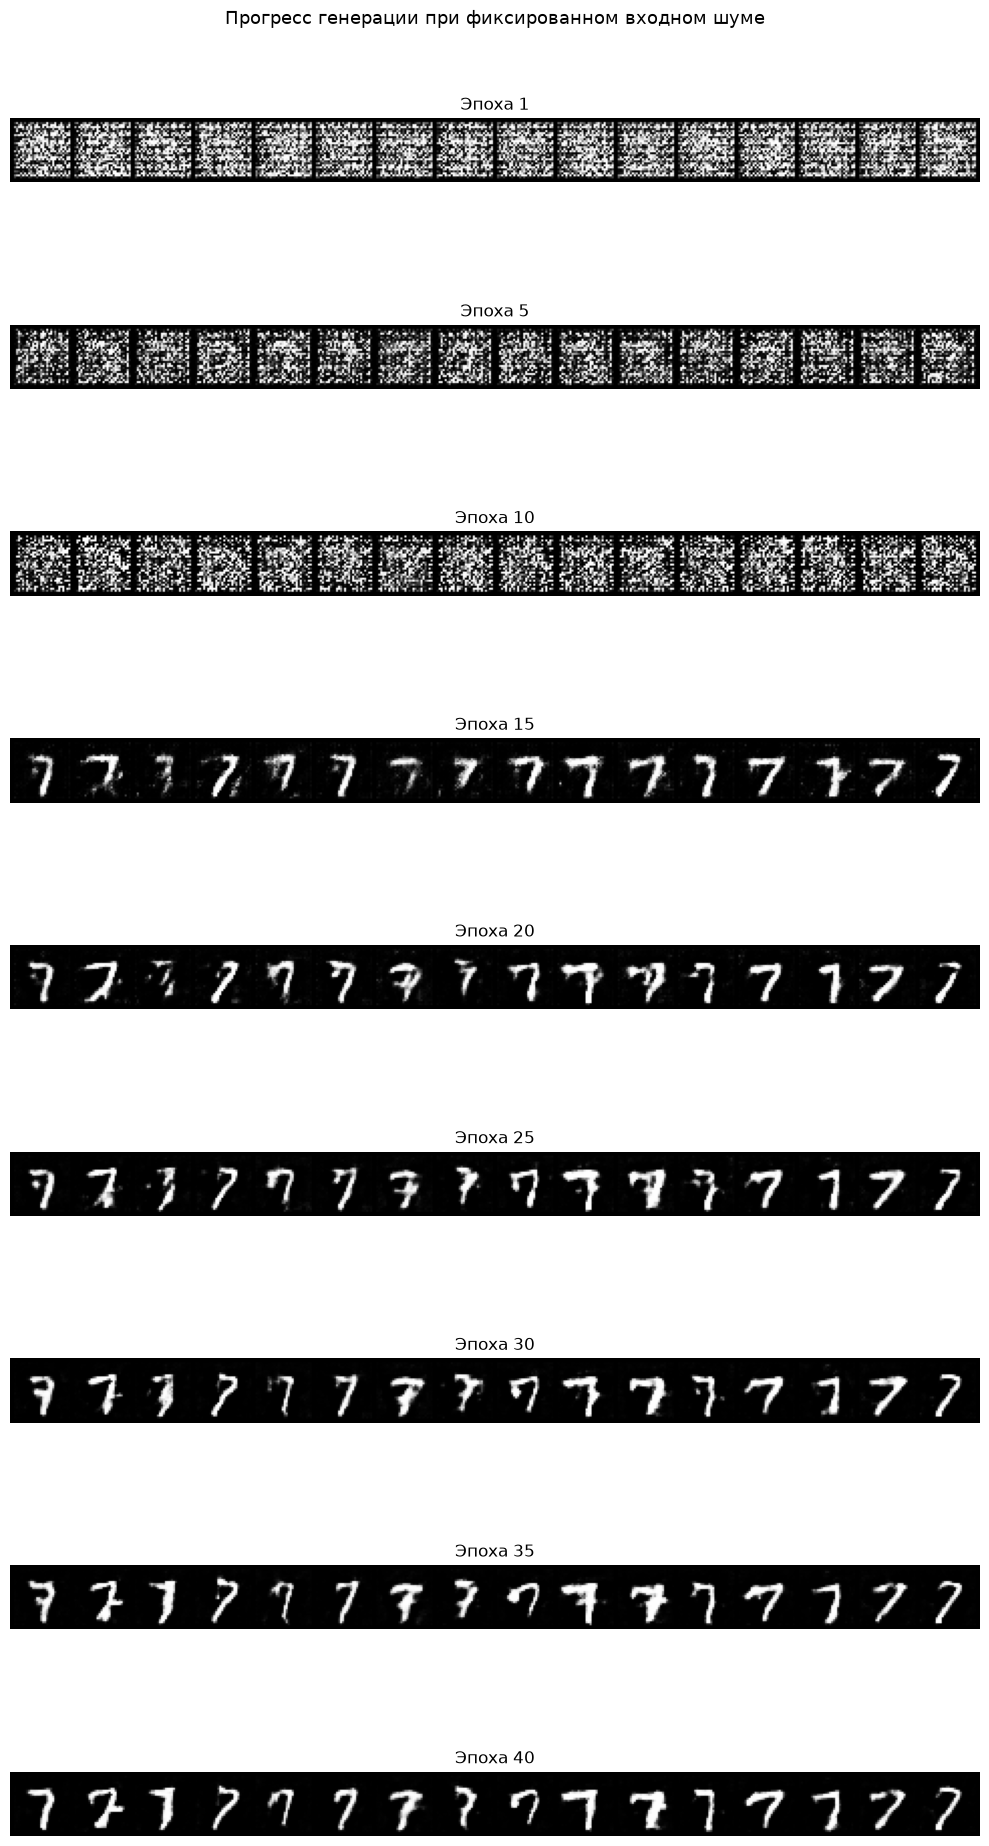

In [8]:
n_snapshots = len(snapshots)
fig, axes = plt.subplots(n_snapshots, 1, figsize=(10, 2.2 * n_snapshots))
if n_snapshots == 1:
    axes = [axes]
for ax, (epoch_num, snapshot) in zip(axes, snapshots):
    grid = make_grid(snapshot[:16], nrow=16, normalize=True)
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_title(f'Эпоха {epoch_num}')
    ax.axis('off')
plt.suptitle('Прогресс генерации при фиксированном входном шуме', fontsize=13)
plt.tight_layout()
plt.show()

---
## Шаг 9. Итоговые сгенерированные изображения и обсуждение качества/артефактов

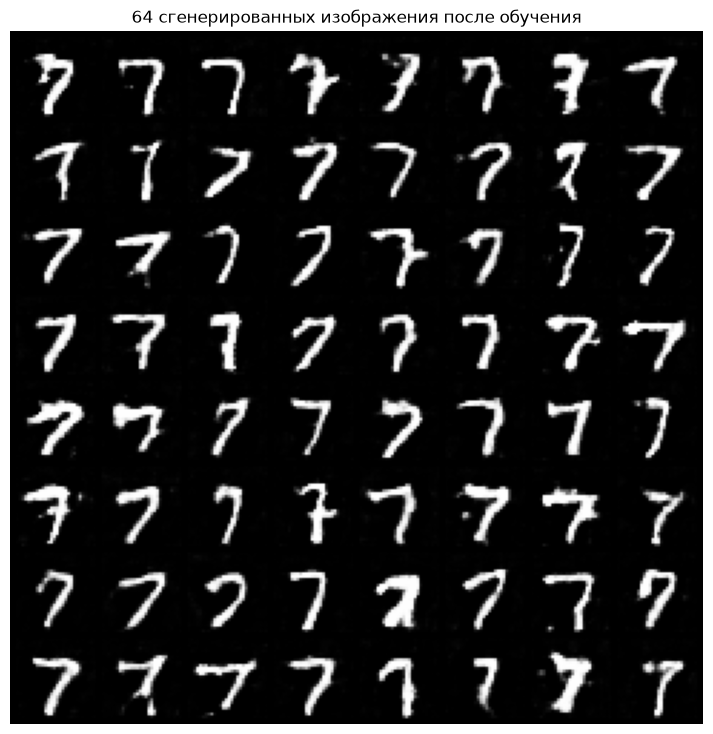

Вопросы для обсуждения по итоговым изображениям:
1. Насколько разнообразны сгенерированные цифры, или заметны повторяющиеся штрихи/формы?
2. Присутствуют ли типичные артефакты: смазанные края, разрывы штриха, нехарактерные для реальной цифры формы?
3. Соответствует ли качество ожиданиям для облегчённой архитектуры и малого числа эпох?


In [9]:
generator.eval()
with torch.no_grad():
    final_noise = torch.randn(64, LATENT_DIM, device=device)
    final_images = generator(final_noise).cpu()

grid = make_grid(final_images, nrow=8, normalize=True)
plt.figure(figsize=(9, 9))
plt.imshow(grid.permute(1, 2, 0))
plt.title('64 сгенерированных изображения после обучения')
plt.axis('off')
plt.show()

print('Вопросы для обсуждения по итоговым изображениям:')
print('1. Насколько разнообразны сгенерированные цифры, или заметны повторяющиеся штрихи/формы?')
print('2. Присутствуют ли типичные артефакты: смазанные края, разрывы штриха, нехарактерные для реальной цифры формы?')
print('3. Соответствует ли качество ожиданиям для облегчённой архитектуры и малого числа эпох?')

---
## Шаг 10. Демонстрация схлопывания мод (mode collapse) на контрольном примере

Обучим отдельную, намеренно упрощённую и плохо сбалансированную GAN (генератор
обучается значительно чаще дискриминатора) на короткое число эпох, чтобы
наглядно спровоцировать схлопывание мод.

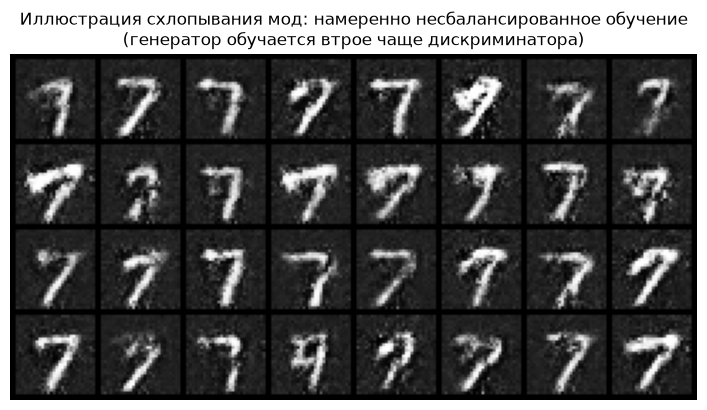

Обратите внимание на выраженное сходство сгенерированных изображений между собой --
признак того, что генератор нашёл узкое подмножество образов, устойчиво обманывающих
слабый дискриминатор, и не имеет стимула порождать более широкое разнообразие форм.


In [10]:
generator_collapse = Generator().to(device)
discriminator_collapse = Discriminator().to(device)
optimizer_G_c = torch.optim.Adam(generator_collapse.parameters(), lr=5e-4, betas=(0.5, 0.999))
optimizer_D_c = torch.optim.Adam(discriminator_collapse.parameters(), lr=5e-5, betas=(0.5, 0.999))  # намеренно медленный дискриминатор

for epoch in range(15):
    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        discriminator_collapse.zero_grad()
        real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)
        loss_D_real = criterion(discriminator_collapse(real_images), real_labels)
        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = generator_collapse(noise)
        fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)
        loss_D_fake = criterion(discriminator_collapse(fake_images.detach()), fake_labels)
        (loss_D_real + loss_D_fake).backward()
        optimizer_D_c.step()

        # Генератор обучается три раза чаще дискриминатора -- намеренный дисбаланс
        for _ in range(3):
            generator_collapse.zero_grad()
            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            fake_images = generator_collapse(noise)
            loss_G = criterion(discriminator_collapse(fake_images), real_labels)
            loss_G.backward()
            optimizer_G_c.step()

with torch.no_grad():
    collapse_samples = generator_collapse(torch.randn(32, LATENT_DIM, device=device)).cpu()

grid_collapse = make_grid(collapse_samples, nrow=8, normalize=True)
plt.figure(figsize=(9, 4.5))
plt.imshow(grid_collapse.permute(1, 2, 0))
plt.title('Иллюстрация схлопывания мод: намеренно несбалансированное обучение\n(генератор обучается втрое чаще дискриминатора)')
plt.axis('off')
plt.show()

print('Обратите внимание на выраженное сходство сгенерированных изображений между собой --')
print('признак того, что генератор нашёл узкое подмножество образов, устойчиво обманывающих')
print('слабый дискриминатор, и не имеет стимула порождать более широкое разнообразие форм.')

---
## Шаг 11. Мини-обсуждение: GAN для суперразрешения и реставрации снимков

Согласно теоретическому материалу, реставрация изображения
формально эквивалентна задаче генерации: сеть должна восстановить
правдоподобное содержание там, где исходная информация утрачена. Реализуем
упрощённый пример: обучим автокодировщик в состязательном режиме на задаче
устранения шума (denoising) с той же обучающей подвыборкой цифр.

In [11]:
class RestorationGenerator(nn.Module):
    """Генератор-реставратор: принимает повреждённое (шумное) изображение, выдаёт восстановленное."""

    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(True),   # 28x28 -> 14x14
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(True),  # 14x14 -> 7x7
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(True),  # 7x7 -> 14x14
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh(),        # 14x14 -> 28x28
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


restoration_generator = RestorationGenerator().to(device)
restoration_discriminator = Discriminator().to(device)
optimizer_RG = torch.optim.Adam(restoration_generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_RD = torch.optim.Adam(restoration_discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

reconstruction_criterion = nn.L1Loss()  # дополнительная прямая функция потерь для сохранения содержания
NOISE_STD = 0.6

for epoch in range(20):
    for real_images, _ in dataloader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)
        noisy_images = torch.clamp(real_images + NOISE_STD * torch.randn_like(real_images), -1, 1)

        restoration_discriminator.zero_grad()
        real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)
        loss_RD_real = criterion(restoration_discriminator(real_images), real_labels)
        restored_images = restoration_generator(noisy_images)
        fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)
        loss_RD_fake = criterion(restoration_discriminator(restored_images.detach()), fake_labels)
        (loss_RD_real + loss_RD_fake).backward()
        optimizer_RD.step()

        restoration_generator.zero_grad()
        restored_images = restoration_generator(noisy_images)
        adv_loss = criterion(restoration_discriminator(restored_images), real_labels)
        rec_loss = reconstruction_criterion(restored_images, real_images)
        total_loss_RG = adv_loss + 10.0 * rec_loss  # приоритет сохранению содержания изображения
        total_loss_RG.backward()
        optimizer_RG.step()

print('Обучение генератора-реставратора завершено.')

Обучение генератора-реставратора завершено.


---
## Шаг 12. Визуальное сравнение: повреждённое, восстановленное, эталонное изображение

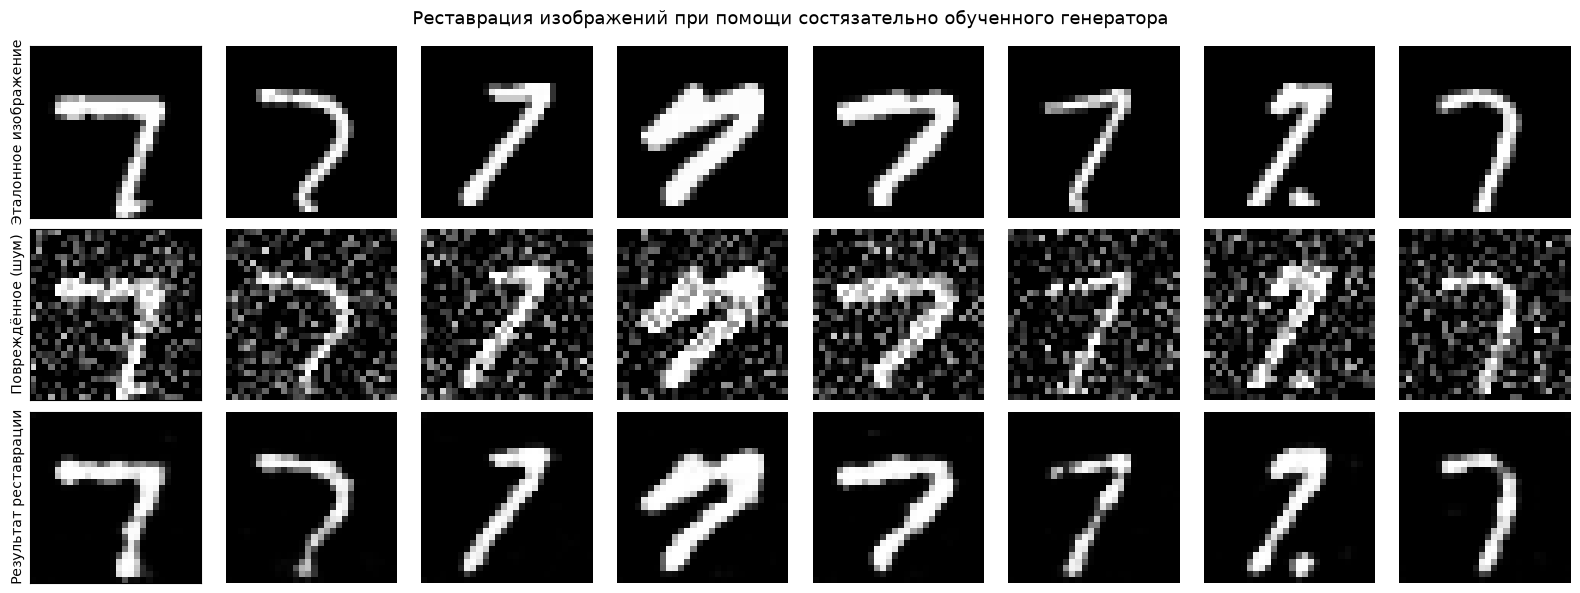

Среднеквадратичная ошибка до реставрации:  0.1765
Среднеквадратичная ошибка после реставрации: 0.0357
Относительное улучшение: 79.8%


In [12]:
restoration_generator.eval()
sample_real, _ = next(iter(dataloader))
sample_real = sample_real[:8].to(device)
sample_noisy = torch.clamp(sample_real + NOISE_STD * torch.randn_like(sample_real), -1, 1)
with torch.no_grad():
    sample_restored = restoration_generator(sample_noisy)

fig, axes = plt.subplots(3, 8, figsize=(16, 6))
for i in range(8):
    axes[0, i].imshow(sample_real[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(sample_noisy[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
    axes[2, i].imshow(sample_restored[i, 0].cpu(), cmap='gray'); axes[2, i].axis('off')
for ax, label in zip([axes[0,0], axes[1,0], axes[2,0]], ['Эталонное изображение', 'Повреждённое (шум)', 'Результат реставрации']):
    ax.axis('on'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_ylabel(label, fontsize=10)
plt.suptitle('Реставрация изображений при помощи состязательно обученного генератора', fontsize=13)
plt.tight_layout()
plt.show()

mse_before = torch.mean((sample_noisy - sample_real) ** 2).item()
mse_after = torch.mean((sample_restored - sample_real) ** 2).item()
print(f'Среднеквадратичная ошибка до реставрации:  {mse_before:.4f}')
print(f'Среднеквадратичная ошибка после реставрации: {mse_after:.4f}')
print(f'Относительное улучшение: {(1 - mse_after/mse_before)*100:.1f}%')

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | MNIST, подвыборка 2000 изображений одной цифры |
| Архитектура | DCGAN: транспонированные свёртки, пакетная нормализация, ReLU/Tanh, LeakyReLU |
| Обучение | Состязательное обучение, чередование шагов D и G |
| Визуализация | Кривые потерь и точности, прогресс генерации по эпохам, итоговая сетка изображений |
| Демонстрация проблемы | Схлопывание мод при искусственно несбалансированном обучении |
| Прикладное расширение | Реставрация (устранение шума) через состязательно обученный автокодировщик |

---
## Домашнее задание

1. **Основное.** Обучите DCGAN на другой цифре (например, «3» или «8») и
   сравните итоговое качество генерации и скорость сходимости кривых потерь
   с результатом, полученным для цифры «7» в этом ноутбуке. Предложите
   гипотезу, объясняющую возможные различия (например, связанную со
   сложностью формы цифры).

2. **Условная генерация.** Модифицируйте архитектуру генератора и
   дискриминатора для реализации условной GAN: добавьте метку класса цифры как дополнительный вход (например,
   через one-hot вектор, конкатенированный с шумом для генератора и с
   изображением для дискриминатора) и обучите модель генерировать цифры
   заданного класса по требованию, используя все десять цифр MNIST.

3. **Количественная оценка схлопывания мод.** Для эксперимента Шага 10
   вычислите попарные расстояния (например, среднеквадратичную ошибку) между
   32 сгенерированными изображениями и постройте гистограмму этих расстояний.
   Сравните полученную гистограмму с аналогичной гистограммой для итоговых
   изображений из Шага 9 (полноценно обученная модель). Подтвердите или
   опровергните наличие схлопывания мод количественно, а не только визуально.

4. **(Дополнительно)** Увеличьте уровень шума (NOISE_STD) в Шаге 11 до 0.9 и
   заново обучите генератор-реставратор. Проанализируйте, при каком уровне
   повреждения качество восстановления становится неудовлетворительным.

5. **(Дополнительно)** Изучите влияние коэффициента при `rec_loss` в формуле
   `total_loss_RG` (Шаг 11, сейчас равен 10.0) на результат: обучите модель с
   коэффициентами 1.0 и 50.0 и сравните визуальное качество и среднеквадратичную
   ошибку восстановления. Объясните наблюдаемый эффект с точки зрения баланса
   между реалистичностью (состязательная составляющая) и точностью
   воспроизведения содержания (прямая составляющая).